In [18]:
import matplotlib.pyplot as plt
import numpy as np
import struct
import time

In [19]:
class MNIST_dataset:
  def __init__(self, images_file, labels_file, batch_size: int = 1, shuffle: bool = False):
    with open(images_file, 'rb') as file:
      magic, num_elem, self.img_h, self.img_w = struct.unpack('>IIII', file.read(16))
      buf = file.read(num_elem * self.img_h * self.img_w)
      data = np.frombuffer(buf, dtype=np.uint8)
      self.images = data.reshape(num_elem, self.img_h * self.img_w)

    with open(labels_file, 'rb') as file:
      magic, num_elem = struct.unpack('>II', file.read(8))
      buf = file.read(num_elem)
      self.labels = np.frombuffer(buf, dtype=np.uint8)

    self.batch_size = batch_size
    self.shuffle = shuffle


  def __len__(self):
    return len(self.labels)


  def __getitem__(self, index):
    return self.images[index].reshape(self.img_h, self.img_w), self.labels[index]


  def __iter__(self):
    indices = np.arange(len(self))
    if self.shuffle:
      np.random.shuffle(indices)
    for i in range(0, len(indices), self.batch_size):
      batch_idx = indices[i:i + self.batch_size]
      yield self.images[batch_idx], self.labels[batch_idx]

Обучающая выборка: 60000 примеров
Тестовая выборка: 10000 примеров
Форма изображения: (28, 28)
Тип метки: <class 'numpy.uint8'>, значение: 5


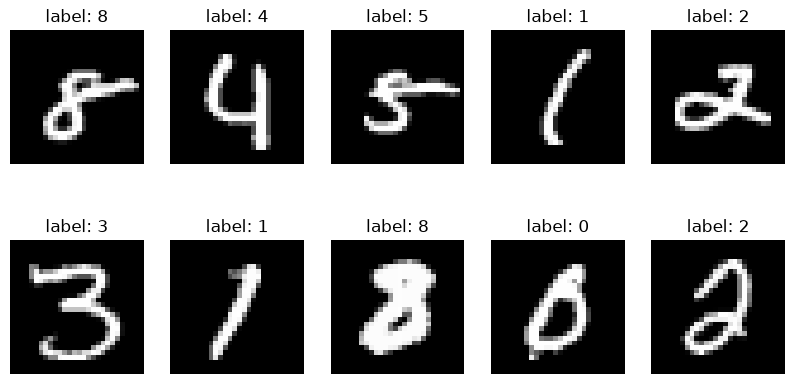

In [20]:
train_dataset = MNIST_dataset('data/train-images.idx3-ubyte', 'data/train-labels.idx1-ubyte', batch_size=10, shuffle=True)
test_dataset = MNIST_dataset('data/t10k-images.idx3-ubyte', 'data/t10k-labels.idx1-ubyte', batch_size=10, shuffle=False)

print(f"Обучающая выборка: {len(train_dataset)} примеров")
print(f"Тестовая выборка: {len(test_dataset)} примеров")

sample_img, sample_label = train_dataset[0]
print(f"Форма изображения: {sample_img.shape}")
print(f"Тип метки: {type(sample_label)}, значение: {sample_label}")

fig, axes = plt.subplots(2, 5, figsize=(10, 5))

start_idx = np.random.randint(0, len(train_dataset) - 10);
indices = range(start_idx, start_idx + 10)

for i, ax in zip(indices, axes.flat):
  image, label = train_dataset[i]
  
  ax.imshow(image, cmap='gray')
  ax.set_title(f'label: {label}')
  ax.axis('off')

plt.show()

In [21]:
def ReLU(x):
  return np.maximum(0, x)


def softmax(x):
  max_x = np.max(x, axis=-1, keepdims=True)
  shifted_x = x - max_x
  exp_x = np.exp(shifted_x)
  sum_exp = np.sum(exp_x, axis=-1, keepdims=True)
  
  probs = exp_x / sum_exp

  return probs


def cross_entropy_loss(label_pred, label_true):
    eps = 1e-15
    label_pred = np.clip(label_pred, eps, 1 - eps)

    batch_indices = np.arange(len(label_true))
    target_probs = label_pred[batch_indices, label_true]

    log_probs = np.log(target_probs)
    loss = -np.mean(log_probs)
    
    return loss


def evaluate(data_loader, model):
  tp = 0
  n = 0

  for images, labels in data_loader:
    images = images / 255.0

    outputs = model.forward(images)
    predicted = np.argmax(outputs, axis=1)
    
    n += len(labels)
    tp += np.sum(predicted == labels)
    
  accuracy = tp / n
  error_rate = 1.0 - accuracy
  return accuracy, error_rate

In [ ]:
class DeepNN:
  def __init__(self, input_size=784, hidden_size=300, output_size=10):
    limitW1 = np.sqrt(6.0 / input_size)
    self.W1 = np.random.uniform(-limitW1, limitW1, (input_size, hidden_size))
    self.b1 = np.zeros((1, hidden_size))
    limitW2 = np.sqrt(3.0 / hidden_size)
    self.W2 = np.random.uniform(-limitW2, limitW2, (hidden_size, output_size))
    self.b2 = np.zeros((1, output_size))


  def forward(self, images):
    self.v1 = np.dot(images, self.W1) + self.b1
    self.v2 = ReLU(self.v1)
    self.v3 = np.dot(self.v2, self.W2) + self.b2
    self.v6 = softmax(self.v3)
    return self.v6


  def backward(self, images, labels):
    batch_size = images.shape[0]

    dL_dv3 = self.v6.copy()
    dL_dv3[np.arange(batch_size), labels] -= 1.0

    self.dW2 = np.dot(self.v2.T, dL_dv3) / batch_size
    self.db2 = np.sum(dL_dv3, axis=0, keepdims=True) / batch_size
    dL_dv2 = np.dot(dL_dv3, self.W2.T)

    dL_dv1 = dL_dv2 * (self.v1 > 0)

    self.dW1 = np.dot(images.T, dL_dv1) / batch_size
    self.db1 = np.sum(dL_dv1, axis=0, keepdims=True) / batch_size


  def train(self, dataset, epochs, lr):
    for epoch in range(epochs):
      start_time = time.time()

      for images, labels in dataset:
        images = images / 255.0
        self.forward(images)

        self.backward(images, labels)

        self.W1 -= lr * self.dW1
        self.b1 -= lr * self.db1
        self.W2 -= lr * self.dW2
        self.b2 -= lr * self.db2

      epoch_time = time.time() - start_time
      _, train_error = evaluate(dataset, self)

      print(f"Эпоха [{epoch + 1}/{epochs}]: "
            f"ошибка на трейне: {train_error * 100:.2f}% | "
            f"время выполнения: {epoch_time:.2f}s")


In [23]:
train_dataset = MNIST_dataset('data/train-images.idx3-ubyte', 'data/train-labels.idx1-ubyte', batch_size=64, shuffle=True)
test_dataset = MNIST_dataset('data/t10k-images.idx3-ubyte', 'data/t10k-labels.idx1-ubyte', batch_size=64, shuffle=False)

model = DeepNN(input_size=784, hidden_size=300, output_size=10)

model.train(train_dataset, epochs=20, lr=0.1)

_, test_error = evaluate(test_dataset, model)
print(f"Ошибка на тесте: {test_error * 100:.2f}%")

Эпоха [1/20]: ошибка на трейне: 6.99% | время выполнения: 1.92s
Эпоха [2/20]: ошибка на трейне: 4.65% | время выполнения: 2.19s
Эпоха [3/20]: ошибка на трейне: 3.73% | время выполнения: 1.73s
Эпоха [4/20]: ошибка на трейне: 2.94% | время выполнения: 2.12s
Эпоха [5/20]: ошибка на трейне: 2.25% | время выполнения: 1.75s
Эпоха [6/20]: ошибка на трейне: 2.08% | время выполнения: 1.72s
Эпоха [7/20]: ошибка на трейне: 1.70% | время выполнения: 1.72s
Эпоха [8/20]: ошибка на трейне: 1.37% | время выполнения: 2.57s
Эпоха [9/20]: ошибка на трейне: 1.27% | время выполнения: 2.34s
Эпоха [10/20]: ошибка на трейне: 0.99% | время выполнения: 1.89s
Эпоха [11/20]: ошибка на трейне: 1.01% | время выполнения: 1.94s
Эпоха [12/20]: ошибка на трейне: 0.85% | время выполнения: 2.43s
Эпоха [13/20]: ошибка на трейне: 0.73% | время выполнения: 2.31s
Эпоха [14/20]: ошибка на трейне: 1.03% | время выполнения: 2.37s
Эпоха [15/20]: ошибка на трейне: 0.55% | время выполнения: 2.09s
Эпоха [16/20]: ошибка на трейне: 0